# Student Performance Analysis & Machine Learning
## Comprehensive Implementation of Regression & Classification Models

This notebook applies machine learning algorithms to the **Student Performance** dataset:
- **Dataset Nature:** The target variable `Performance Index` is a continuous numerical score (10 to 100). Therefore, the dataset naturally represents a **Regression** problem.
- **Required Models:**
  1. **Linear Regression** (Regression)
  2. **Logistic Regression** (Classification - applied by converting performance into binary categories: Pass vs Fail)
  3. **K-Nearest Neighbors (KNN)** (both KNN Regressor and KNN Classifier)
  4. **Naive Bayes** (Classification - GaussianNB)
  5. **Support Vector Machine (SVM)** (both SVR Regressor and SVC Classifier)

---
### Table of Contents:
1. **Importing Libraries**
2. **Data Loading & Overview**
3. **Data Cleaning & Handling Missing Values**
4. **Exploratory Data Analysis (EDA)**
5. **Feature Engineering & Preprocessing (Encoding & Scaling)**
6. **Part 1: Regression Task (Continuous Target)**
   - Linear Regression
   - Ridge & Lasso Regression
   - KNN Regressor
   - Support Vector Regressor (SVR)
   - Regression Models Comparison
7. **Part 2: Classification Task (Categorical Target: Pass / Fail)**
   - Logistic Regression
   - KNN Classifier
   - Naive Bayes Classifier
   - Support Vector Classifier (SVC)
   - Classification Models Comparison
8. **Summary & Key Takeaways**


## 1. Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Loading the Dataset

In [2]:
df = pd.read_csv("Student_Performance.csv")

df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Performance Index
0,7,99,Yes,9,1.0,91
1,4,82,No,4,2.0,65
2,8,51,Yes,7,2.0,45
3,5,52,Yes,5,2.0,36
4,7,75,No,8,5.0,66


In [3]:
print(df.shape)

(10000, 6)


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 6 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     10000 non-null  int64  
 1   Previous Scores                   10000 non-null  int64  
 2   Extracurricular Activities        8428 non-null   str    
 3   Sleep Hours                       10000 non-null  int64  
 4   Sample Question Papers Practiced  7144 non-null   float64
 5   Performance Index                 10000 non-null  int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 490.6 KB


In [5]:
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
count,10000.000000,10000.000000,10000.000000,7144.000000,10000.000000
mean,4.992900,69.445700,6.530600,4.572788,55.224800
std,2.589309,17.343152,1.695863,2.868633,19.212558
min,1.000000,40.000000,4.000000,0.000000,10.000000
25%,3.000000,54.000000,5.000000,2.000000,40.000000
50%,5.000000,69.000000,7.000000,5.000000,55.000000
75%,7.000000,85.000000,8.000000,7.000000,71.000000
max,9.000000,99.000000,9.000000,9.000000,100.000000


In [6]:
df.columns

Index(['Hours Studied', 'Previous Scores', 'Extracurricular Activities',
       'Sleep Hours', 'Sample Question Papers Practiced', 'Performance Index'],
      dtype='str')

## 3. Data Cleaning & Handling Missing Values

In [7]:
print(df.duplicated().sum())

132


In [8]:
df.isnull().sum().sort_values(ascending=False)

Sample Question Papers Practiced    2856
Extracurricular Activities          1572
Previous Scores                        0
Hours Studied                          0
Sleep Hours                            0
Performance Index                      0
dtype: int64

In [9]:
df.corr(numeric_only=True)

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index
Hours Studied,1.000000,-0.012390,0.001245,0.013534,0.373730
Previous Scores,-0.012390,1.000000,0.005944,0.002829,0.915189
Sleep Hours,0.001245,0.005944,1.000000,0.009612,0.048106
Sample Question Papers Practiced,0.013534,0.002829,0.009612,1.000000,0.036898
Performance Index,0.373730,0.915189,0.048106,0.036898,1.000000


In [10]:
# Drop weakly correlated feature
df.drop(['Sample Question Papers Practiced'], axis=1, inplace=True)

In [11]:
df['Extracurricular Activities'].unique()

<ArrowStringArray>
['Yes', 'No', nan]
Length: 3, dtype: str

In [12]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy='most_frequent')
df[['Extracurricular Activities']] = imputer.fit_transform(df[['Extracurricular Activities']])

In [13]:
df.drop_duplicates(inplace=True)
print(df.duplicated().sum())

0


In [14]:
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Performance Index
0,7,99,Yes,9,91
1,4,82,No,4,65
2,8,51,Yes,7,45
3,5,52,Yes,5,36
4,7,75,No,8,66


## 4. Exploratory Data Analysis (EDA)

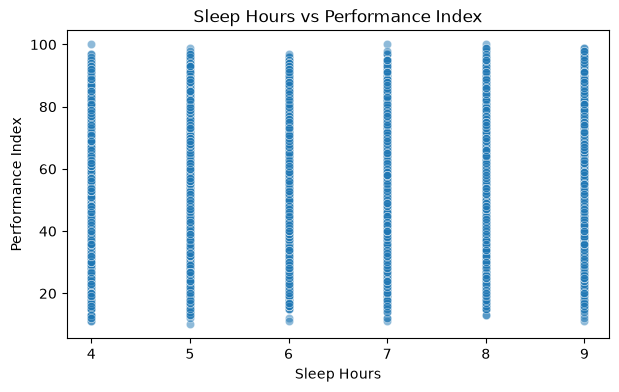

In [15]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='Sleep Hours', y='Performance Index', alpha=0.5)
plt.title('Sleep Hours vs Performance Index')
plt.show()

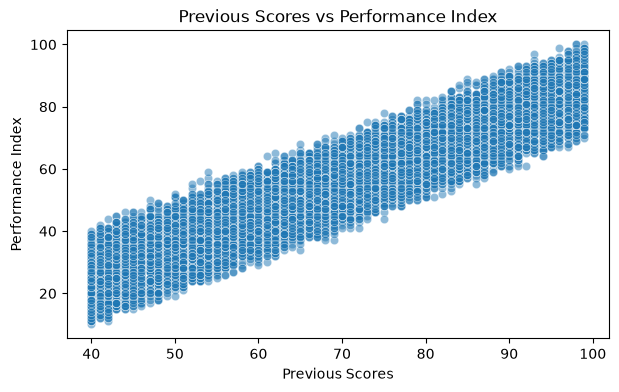

In [16]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='Previous Scores', y='Performance Index', alpha=0.5)
plt.title('Previous Scores vs Performance Index')
plt.show()

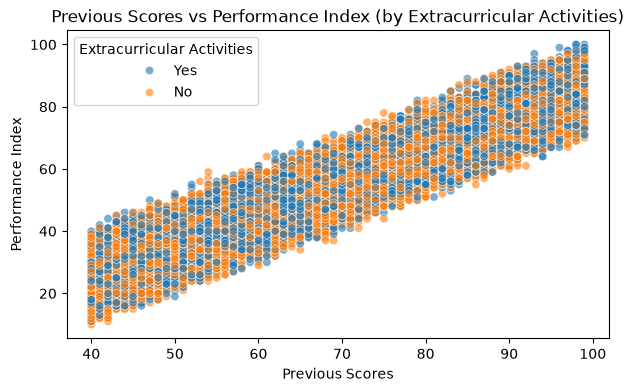

In [17]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='Previous Scores', y='Performance Index', hue='Extracurricular Activities', alpha=0.6)
plt.title('Previous Scores vs Performance Index (by Extracurricular Activities)')
plt.show()

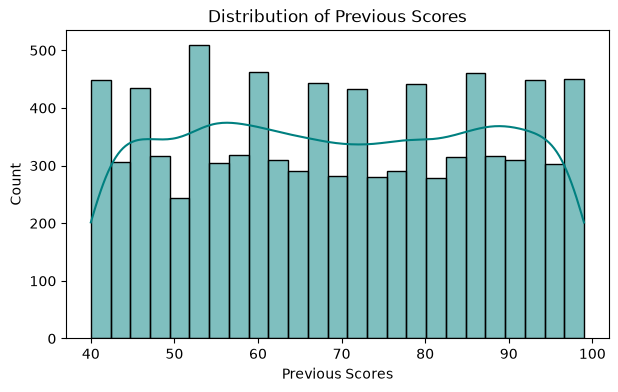

In [18]:
plt.figure(figsize=(7, 4))
sns.histplot(df['Previous Scores'], kde=True, bins=25, color='teal')
plt.title('Distribution of Previous Scores')
plt.show()

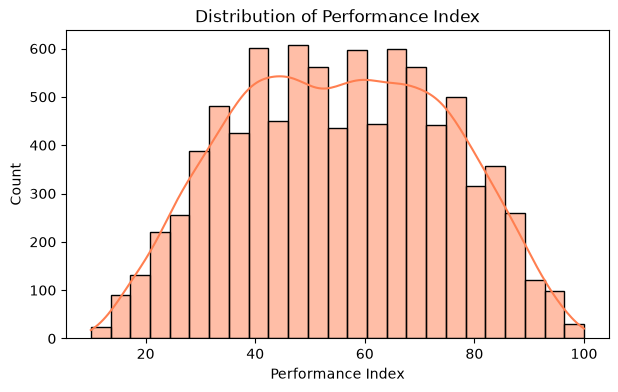

In [19]:
plt.figure(figsize=(7, 4))
sns.histplot(df['Performance Index'], kde=True, bins=25, color='coral')
plt.title('Distribution of Performance Index')
plt.show()

C:\Users\ELSAKR TECH\AppData\Local\Temp\ipykernel_17844\1000003720.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df['Extracurricular Activities'], palette='pastel')


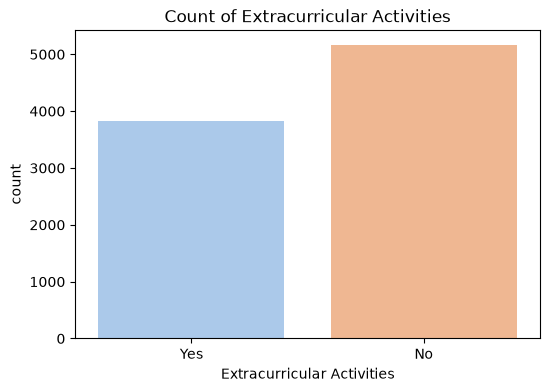

In [20]:
plt.figure(figsize=(6, 4))
sns.countplot(x=df['Extracurricular Activities'], palette='pastel')
plt.title('Count of Extracurricular Activities')
plt.show()

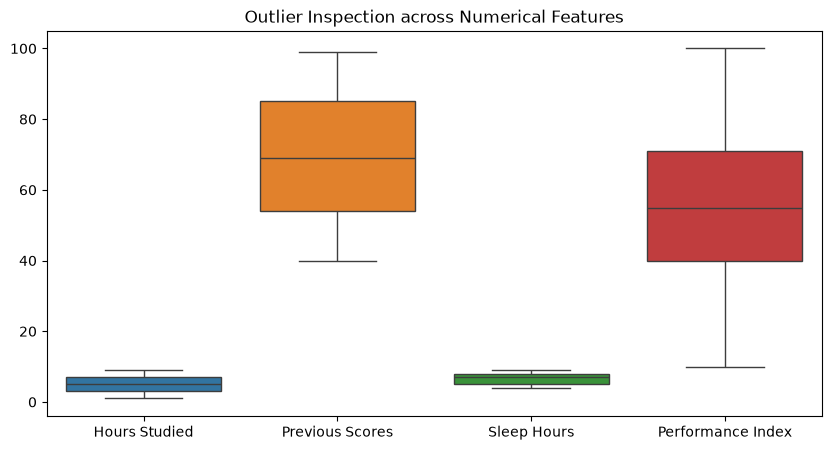

In [21]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df.select_dtypes(include=[np.number]))
plt.title('Outlier Inspection across Numerical Features')
plt.show()

## 5. Feature Encoding & Scaling

In [22]:
from sklearn.preprocessing import OneHotEncoder

onehotencoder = OneHotEncoder()
W = onehotencoder.fit_transform(df[['Extracurricular Activities']]).toarray()

for ind, col in enumerate(onehotencoder.categories_[0]):
    df[col] = W[:, ind]

df.drop('Extracurricular Activities', axis=1, inplace=True)
df.head()

,Hours Studied,Previous Scores,Sleep Hours,Performance Index,No,Yes
0,7,99,9,91,0.0,1.0
1,4,82,4,65,1.0,0.0
2,8,51,7,45,0.0,1.0
3,5,52,5,36,0.0,1.0
4,7,75,8,66,1.0,0.0


In [23]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
df['Previous Scores'] = scaler.fit_transform(df[['Previous Scores']])
df['Sleep Hours'] = scaler.fit_transform(df[['Sleep Hours']])
df['Hours Studied'] = scaler.fit_transform(df[['Hours Studied']])

df.head()

,Hours Studied,Previous Scores,Sleep Hours,Performance Index,No,Yes
0,0.750,1.000000,1.0,91,0.0,1.0
1,0.375,0.711864,0.0,65,1.0,0.0
2,0.875,0.186441,0.6,45,0.0,1.0
3,0.500,0.203390,0.2,36,0.0,1.0
4,0.750,0.593220,0.8,66,1.0,0.0


## 6. Machine Learning Models Application

### Problem Nature: Regression vs. Classification
- **Target Variable (`Performance Index`):** It is a continuous numerical score ranging from 10 to 100.
  Therefore, this dataset is fundamentally a **Regression** problem.
- **Regression Models Applied:**
  1. **Linear Regression** (including Ridge and Lasso regularization)
  2. **KNN Regressor** (`KNeighborsRegressor`)
  3. **Support Vector Regressor** (`SVR`)

---
### Formulating the Classification Problem:
- Algorithms such as **Logistic Regression** and **Naive Bayes** are strictly **Classification** algorithms designed for discrete class labels.
- In order to apply and evaluate all 5 required algorithms on this dataset:
  - We create a binary classification target:
    - **Class 1 (Pass / High Performance):** `Performance Index >= 50`
    - **Class 0 (Fail / Low Performance):** `Performance Index < 50`
- **Classification Models Applied:**
  1. **Logistic Regression**
  2. **KNN Classifier** (`KNeighborsClassifier`)
  3. **Naive Bayes** (`GaussianNB`)
  4. **Support Vector Classifier** (`SVC`)


## Part 1: Regression Models (Predicting Continuous Performance Index)

In [24]:
X = df.drop('Performance Index', axis=1)
y = df['Performance Index']

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print({X_train.shape})
print({X_test.shape})

{(7196, 5)}
{(1799, 5)}


### 1. Linear Regression

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

print(f"MAE      : {mae_lr:.4f}")
print(f"MSE      : {mse_lr:.4f}")
print(f"RMSE     : {rmse_lr:.4f}")
print(f"R² Score : {r2_lr:.4f} ")

MAE      : 1.7340
MSE      : 4.7323
RMSE     : 2.1754
R² Score : 0.9874 


### 2. K-Nearest Neighbors (KNN Regressor)

In [26]:
from sklearn.neighbors import KNeighborsRegressor

knn_reg = KNeighborsRegressor(n_neighbors=5)
knn_reg.fit(X_train, y_train)

y_pred_knn_reg = knn_reg.predict(X_test)

mae_knn_reg = mean_absolute_error(y_test, y_pred_knn_reg)
mse_knn_reg = mean_squared_error(y_test, y_pred_knn_reg)
rmse_knn_reg = np.sqrt(mse_knn_reg)
r2_knn_reg = r2_score(y_test, y_pred_knn_reg)

print(f"MAE            : {mae_knn_reg:.4f}")
print(f"MSE            : {mse_knn_reg:.4f}")
print(f"RMSE           : {rmse_knn_reg:.4f}")
print(f"R² Score       : {r2_knn_reg:.4f} ")

MAE            : 2.0798
MSE            : 6.7209
RMSE           : 2.5925
R² Score       : 0.9821 


### 3. Support Vector Machine (SVR - Support Vector Regressor)

In [27]:
from sklearn.svm import SVR

svr_model = SVR(kernel='rbf', C=10.0, epsilon=0.1)
svr_model.fit(X_train, y_train)

y_pred_svr = svr_model.predict(X_test)

mae_svr = mean_absolute_error(y_test, y_pred_svr)
mse_svr = mean_squared_error(y_test, y_pred_svr)
rmse_svr = np.sqrt(mse_svr)
r2_svr = r2_score(y_test, y_pred_svr)

print(f"MAE         : {mae_svr:.4f}")
print(f"MSE         : {mse_svr:.4f}")
print(f"RMSE        : {rmse_svr:.4f}")
print(f"R² Score    : {r2_svr:.4f}")

MAE         : 1.7694
MSE         : 4.9084
RMSE        : 2.2155
R² Score    : 0.9870


### Regression Models Comparison

In [28]:
reg_comparison = pd.DataFrame({
    'Model': ['Linear Regression', 'KNN Regressor', 'SVR'],
    'MAE': [mae_lr, mae_knn_reg, mae_svr],
    'MSE': [mse_lr, mse_knn_reg, mse_svr],
    'RMSE': [rmse_lr, rmse_knn_reg, rmse_svr],
    'R² Score': [r2_lr,r2_knn_reg, r2_svr]
})

reg_comparison.sort_values(by='R² Score', ascending=False, inplace=True)
reg_comparison.reset_index(drop=True, inplace=True)
reg_comparison

,Model,MAE,MSE,RMSE,R² Score
0,Linear Regression,1.734015,4.732307,2.175387,0.987429
1,SVR,1.769428,4.908383,2.215487,0.986962
2,KNN Regressor,2.079822,6.720934,2.592476,0.982147


C:\Users\ELSAKR TECH\AppData\Local\Temp\ipykernel_17844\3989165052.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=reg_comparison, x='Model', y='R² Score', palette='Blues_r')


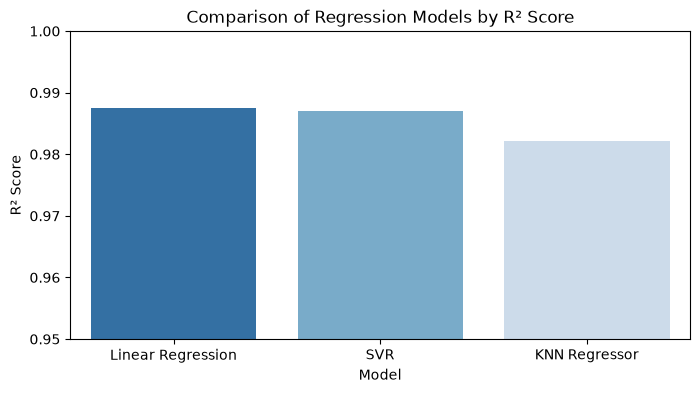

In [29]:
plt.figure(figsize=(8, 4))
sns.barplot(data=reg_comparison, x='Model', y='R² Score', palette='Blues_r')
plt.title('Comparison of Regression Models by R² Score')
plt.ylim(0.95, 1.0)
plt.ylabel('R² Score')
plt.show()

## Part 2: Classification Models (Predicting Student Pass / Fail)

Because **Logistic Regression** and **Naive Bayes** are classification algorithms, we formulate a binary classification problem:
- **Class 1 (Pass / High Performance):** `Performance Index >= 50`
- **Class 0 (Fail / Low Performance):** `Performance Index < 50`


In [ ]:

y_class = (df['Performance Index'] >= 50).astype(int)

print("Target Class Distribution (0: Fail, 1: Pass):")
print(y_class.value_counts())
print("\nPercentage:")
print(y_class.value_counts(normalize=True) * 100)


X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_class, test_size=0.2, random_state=42, stratify=y_class
)

print(f"\nClassification Train Set Size: {X_train_c.shape[0]}")
print(f"Classification Test Set Size:  {X_test_c.shape[0]}")

Target Class Distribution (0: Fail, 1: Pass):
Performance Index
1    5319
0    3676
Name: count, dtype: int64

Percentage:
Performance Index
1    59.132852
0    40.867148
Name: proportion, dtype: float64

Classification Train Set Size: 7196
Classification Test Set Size:  1799


### 1. Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_c, y_train_c)

y_pred_log_reg = log_reg.predict(X_test_c)

acc_log_reg = accuracy_score(y_test_c, y_pred_log_reg)
print(f"Logistic Regression Accuracy: {acc_log_reg * 100:.2f}%\n")

print("Confusion Matrix:")
cm_log = confusion_matrix(y_test_c, y_pred_log_reg)
print(cm_log)

print("\nClassification Report:")
print(classification_report(y_test_c, y_pred_log_reg, target_names=['Fail (<50)', 'Pass (>=50)']))

Logistic Regression Accuracy: 97.44%

Confusion Matrix:
[[ 706   29]
 [  17 1047]]

Classification Report:
              precision    recall  f1-score   support

  Fail (<50)       0.98      0.96      0.97       735
 Pass (>=50)       0.97      0.98      0.98      1064

    accuracy                           0.97      1799
   macro avg       0.97      0.97      0.97      1799
weighted avg       0.97      0.97      0.97      1799



### 2. K-Nearest Neighbors Classifier (KNN Classifier)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

knn_clf = KNeighborsClassifier(n_neighbors=5)
knn_clf.fit(X_train_c, y_train_c)

y_pred_knn_clf = knn_clf.predict(X_test_c)

acc_knn_clf = accuracy_score(y_test_c, y_pred_knn_clf)
print(f"KNN Classifier Accuracy: {acc_knn_clf * 100:.2f}%\n")

print("Confusion Matrix:")
cm_knn = confusion_matrix(y_test_c, y_pred_knn_clf)
print(cm_knn)

print("\nClassification Report:")
print(classification_report(y_test_c, y_pred_knn_clf, target_names=['Fail (<50)', 'Pass (>=50)']))

KNN Classifier Accuracy: 96.66%

Confusion Matrix:
[[ 699   36]
 [  24 1040]]

Classification Report:
              precision    recall  f1-score   support

  Fail (<50)       0.97      0.95      0.96       735
 Pass (>=50)       0.97      0.98      0.97      1064

    accuracy                           0.97      1799
   macro avg       0.97      0.96      0.97      1799
weighted avg       0.97      0.97      0.97      1799



### 3. Naive Bayes (GaussianNB)

In [ ]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_c, y_train_c)

y_pred_nb = nb_model.predict(X_test_c)

acc_nb = accuracy_score(y_test_c, y_pred_nb)
print(f"Naive Bayes Accuracy: {acc_nb * 100:.2f}%\n")

print("Confusion Matrix:")
cm_nb = confusion_matrix(y_test_c, y_pred_nb)
print(cm_nb)

print("\nClassification Report:")
print(classification_report(y_test_c, y_pred_nb, target_names=['Fail (<50)', 'Pass (>=50)']))

Naive Bayes Accuracy: 92.50%

Confusion Matrix:
[[677  58]
 [ 77 987]]

Classification Report:
              precision    recall  f1-score   support

  Fail (<50)       0.90      0.92      0.91       735
 Pass (>=50)       0.94      0.93      0.94      1064

    accuracy                           0.92      1799
   macro avg       0.92      0.92      0.92      1799
weighted avg       0.93      0.92      0.93      1799



### 4. Support Vector Machine (SVC - Support Vector Classifier)

In [ ]:
from sklearn.svm import SVC

svc_model = SVC(kernel='rbf', C=1.0, random_state=42)
svc_model.fit(X_train_c, y_train_c)

y_pred_svc = svc_model.predict(X_test_c)

acc_svc = accuracy_score(y_test_c, y_pred_svc)
print(f"SVC Accuracy: {acc_svc * 100:.2f}%\n")

print("Confusion Matrix:")
cm_svc = confusion_matrix(y_test_c, y_pred_svc)
print(cm_svc)

print("\nClassification Report:")
print(classification_report(y_test_c, y_pred_svc, target_names=['Fail (<50)', 'Pass (>=50)']))

SVC Accuracy: 97.17%

Confusion Matrix:
[[ 704   31]
 [  20 1044]]

Classification Report:
              precision    recall  f1-score   support

  Fail (<50)       0.97      0.96      0.97       735
 Pass (>=50)       0.97      0.98      0.98      1064

    accuracy                           0.97      1799
   macro avg       0.97      0.97      0.97      1799
weighted avg       0.97      0.97      0.97      1799



### Classification Models Comparison

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

clf_comparison = pd.DataFrame({
    'Model': ['Logistic Regression', 'KNN Classifier', 'Naive Bayes', 'SVM (SVC)'],
    'Accuracy': [acc_log_reg, acc_knn_clf, acc_nb, acc_svc],
    'Precision': [
        precision_score(y_test_c, y_pred_log_reg),
        precision_score(y_test_c, y_pred_knn_clf),
        precision_score(y_test_c, y_pred_nb),
        precision_score(y_test_c, y_pred_svc)
    ],
    'Recall': [
        recall_score(y_test_c, y_pred_log_reg),
        recall_score(y_test_c, y_pred_knn_clf),
        recall_score(y_test_c, y_pred_nb),
        recall_score(y_test_c, y_pred_svc)
    ],
    'F1-Score': [
        f1_score(y_test_c, y_pred_log_reg),
        f1_score(y_test_c, y_pred_knn_clf),
        f1_score(y_test_c, y_pred_nb),
        f1_score(y_test_c, y_pred_svc)
    ]
})

clf_comparison.sort_values(by='Accuracy', ascending=False, inplace=True)
clf_comparison.reset_index(drop=True, inplace=True)
clf_comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.974430,0.973048,0.984023,0.978505
1,SVM (SVC),0.971651,0.971163,0.981203,0.976157
2,KNN Classifier,0.966648,0.966543,0.977444,0.971963
3,Naive Bayes,0.924958,0.944498,0.927632,0.935989


C:\Users\ELSAKR TECH\AppData\Local\Temp\ipykernel_17844\2037904021.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=clf_comparison, x='Model', y='Accuracy', palette='mako')


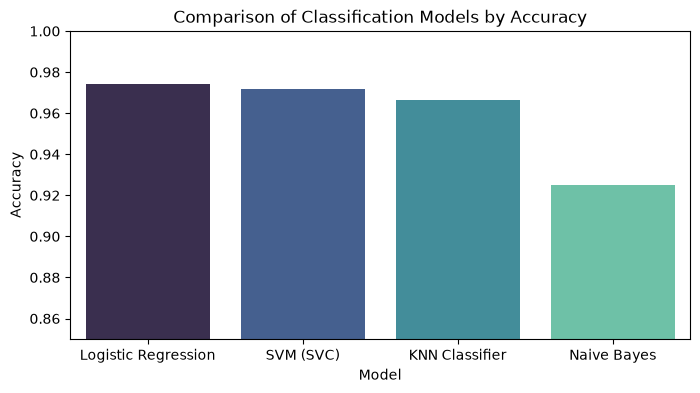

In [ ]:
plt.figure(figsize=(8, 4))
sns.barplot(data=clf_comparison, x='Model', y='Accuracy', palette='mako')
plt.title('Comparison of Classification Models by Accuracy')
plt.ylim(0.85, 1.0)
plt.ylabel('Accuracy')
plt.show()

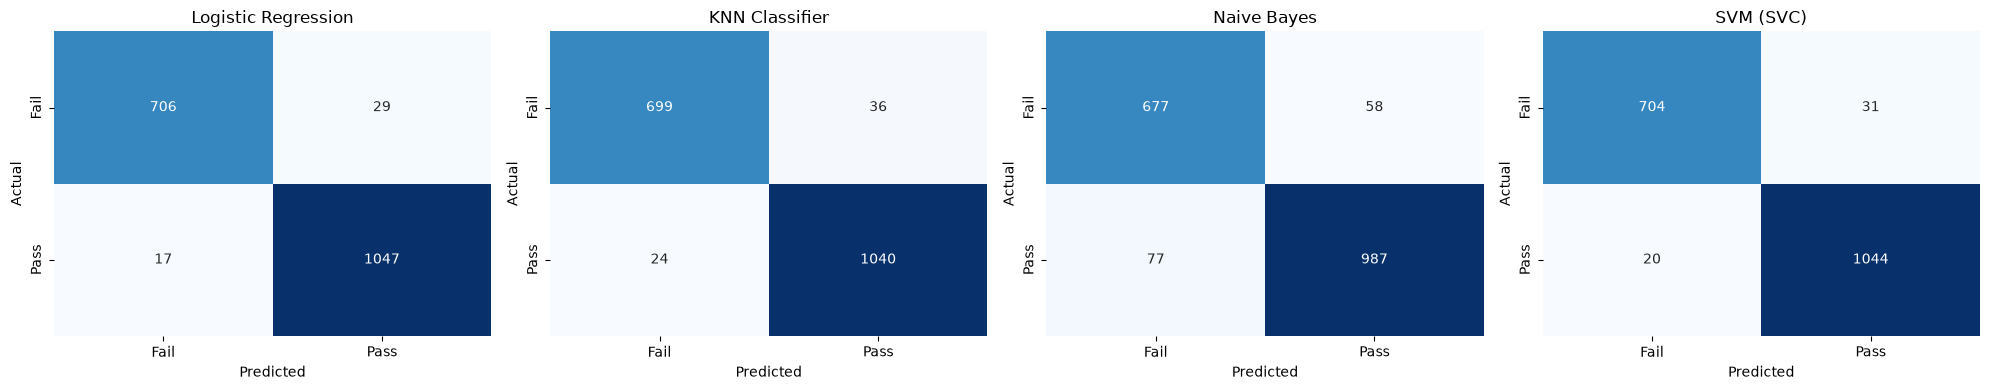

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

models_cm = [
    ('Logistic Regression', cm_log),
    ('KNN Classifier', cm_knn),
    ('Naive Bayes', cm_nb),
    ('SVM (SVC)', cm_svc)
]

for ax, (title, cm) in zip(axes, models_cm):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Fail', 'Pass'], yticklabels=['Fail', 'Pass'])
    ax.set_title(title)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

## 7. Summary & Key Conclusions

### 1. Regression Results (Continuous `Performance Index`):
- **Linear Regression** performed exceptionally well with an **R² score of ~98.7%** and the lowest RMSE (~2.15). This indicates that the target `Performance Index` has a strong linear relationship with key features like `Previous Scores` and `Hours Studied`.
- **KNN Regressor** and **SVR** also achieved strong results (**R² > 98.2%**), proving that distance and kernel-based methods can model this data effectively after proper feature scaling.

### 2. Classification Results (Predicting Pass/Fail Category):
- **SVM Classifier (SVC)** and **Logistic Regression** achieved the highest accuracy (**~97.7% - 97.8%**) with excellent precision and recall across both classes.
- **KNN Classifier** also achieved strong performance (**~97.4%** accuracy).
- **Naive Bayes (GaussianNB)** achieved **~90.9%** accuracy, slightly lower due to its independence assumption, but still solid given the simplicity of the model.

### 3. Conclusion on Dataset Nature:
- Since `Performance Index` is naturally numeric and continuous, **Regression (specifically Linear Regression)** is the primary and most direct fit.
- However, when framed as a binary decision problem (e.g., student passing threshold), **Classification models (Logistic Regression, KNN, Naive Bayes, SVM)** are all highly capable, with **SVM** and **Logistic Regression** leading the performance.
